# 05 — Détection YOLO et deux étages

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/SerreIA/blob/main/notebooks/05_detection.ipynb)

Phase 2 (docs/04-detection-yolo.md) : jeu YOLO `data/yolo/` (PlantDoc + PlantVillage,
classe `feuille`), entraînement du détecteur suivi dans MLflow, puis pipeline deux étages
(YOLO → crops → classifieur de la phase 1) évalué de bout en bout sur PlantDoc TEST.
`YOLO_RUN` renseigné : pas d'entraînement, le run existant est évalué.

Sur Colab : *Exécution → Modifier le type d'exécution → GPU (T4)*.

## Paramètres

In [3]:
CONFIG = "configs/yolo_v8n.yaml"
SET = []  # surcharges, ex. ["yolo.epochs=50", "model=yolov8s.pt"]
DEVICE = None  # None : Ultralytics choisit (GPU 0 s'il y en a un)
YOLO_RUN = None  # run existant (runs/<id>/best.pt) : saute l'entraînement
PV_PER_CLASS = 40  # feuilles PlantVillage par classe dans le jeu YOLO
REBUILD = False  # reconstruit data/yolo/ même s'il existe
CLF_RUN = None  # classifieur de la phase 1 pour les deux étages ; None : le plus récent
LIMIT = 0  # images PlantDoc TEST évaluées (0 : toutes)
DATASETS = ["index", "plantvillage", "plantdoc"]

## Environnement

In [4]:
# Environnement (PC et Colab) : dépôt, données, sorties (docs/data-drive.md).
# PC : rien n'est installé ; un jeu absent est récupéré du Drive par rclone, sinon la cellule
# s'arrête avec la commande à lancer. Colab : clone du dépôt à REV, installation, données via
# le Drive monté (archives MyDrive/SerreIA/data/*.tar), sorties précédentes restaurées.
import logging
import os
import subprocess
import sys
from pathlib import Path

DRIVE_DIR = "/content/drive/MyDrive/SerreIA"  # Colab : data/*.tar et runs/ ; None : pas de Drive
REPO_URL = "https://github.com/lrivals/SerreIA.git"
REV = "main"
COLAB = "google.colab" in sys.modules

if COLAB:
    ROOT = Path("/content/SerreIA")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "--detach", "FETCH_HEAD"], check=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{ROOT}[vision,detection]"], check=True
    )
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", force=True)

from tools.notebooks import drive_data  # noqa: E402

if COLAB and DRIVE_DIR:
    drive_data.mount_drive()
    drive_data.restore_all(DRIVE_DIR)
drive_data.ensure(DATASETS, DRIVE_DIR if COLAB else None)

# Colab : tous les cœurs pour le chargement, base MLflow séparée de celle du PC.
ENV_SET = (
    [f"data.num_workers={os.cpu_count()}", f"mlflow.tracking_uri={drive_data.COLAB_MLFLOW}"]
    if COLAB
    else []
)

Mounted at /content/drive
/content/drive/MyDrive/SerreIA/runs/runs → runs
/content/drive/MyDrive/SerreIA/runs/reports → reports
/content/drive/MyDrive/SerreIA/runs/mlruns/colab → mlruns/colab
$ /content/SerreIA/tools/get_datasets.sh unpack /content/drive/MyDrive/SerreIA/data index
$ /content/SerreIA/tools/get_datasets.sh unpack /content/drive/MyDrive/SerreIA/data plantvillage
$ /content/SerreIA/tools/get_datasets.sh unpack /content/drive/MyDrive/SerreIA/data plantdoc


In [5]:
# Entraînement, évaluation et Grad-CAM tournent sur le GPU, augmentations comprises.
import torch

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
elif COLAB:
    raise RuntimeError("pas de GPU : Exécution → Modifier le type d'exécution → GPU (T4)")
else:
    print("pas de GPU : tout tournera sur CPU (lent)")

GPU : NVIDIA A100-SXM4-80GB


## Jeu YOLO `data/yolo/`

In [6]:
from IPython.display import Image, display

from vision.datasets.build_index import DATA_DIR
from vision.labeling import build_yolo_dataset as byd

YOLO_DIR = DATA_DIR / byd.OUT_NAME
if REBUILD or not (YOLO_DIR / byd.MANIFEST).exists():
    byd.build(DATA_DIR, YOLO_DIR, PV_PER_CLASS, os.cpu_count())

INFO NumExpr defaulting to 12 threads.
WARNING image manquante : NCLB.xml
INFO PlantDoc : 15 images TRAIN quasi-doublons de TEST, écartées



Images par split et source :
split         test  train  val   All
source                              
plantdoc       237   2105  235  2577
plantvillage   185   1480  185  1850
All            422   3585  420  4427

Boîtes par split et source :
split         test  train  val    All
source                               
plantdoc       452   7677  764   8893
plantvillage   185   1480  185   1850
All            637   9157  949  10743

images sans boîte : 11


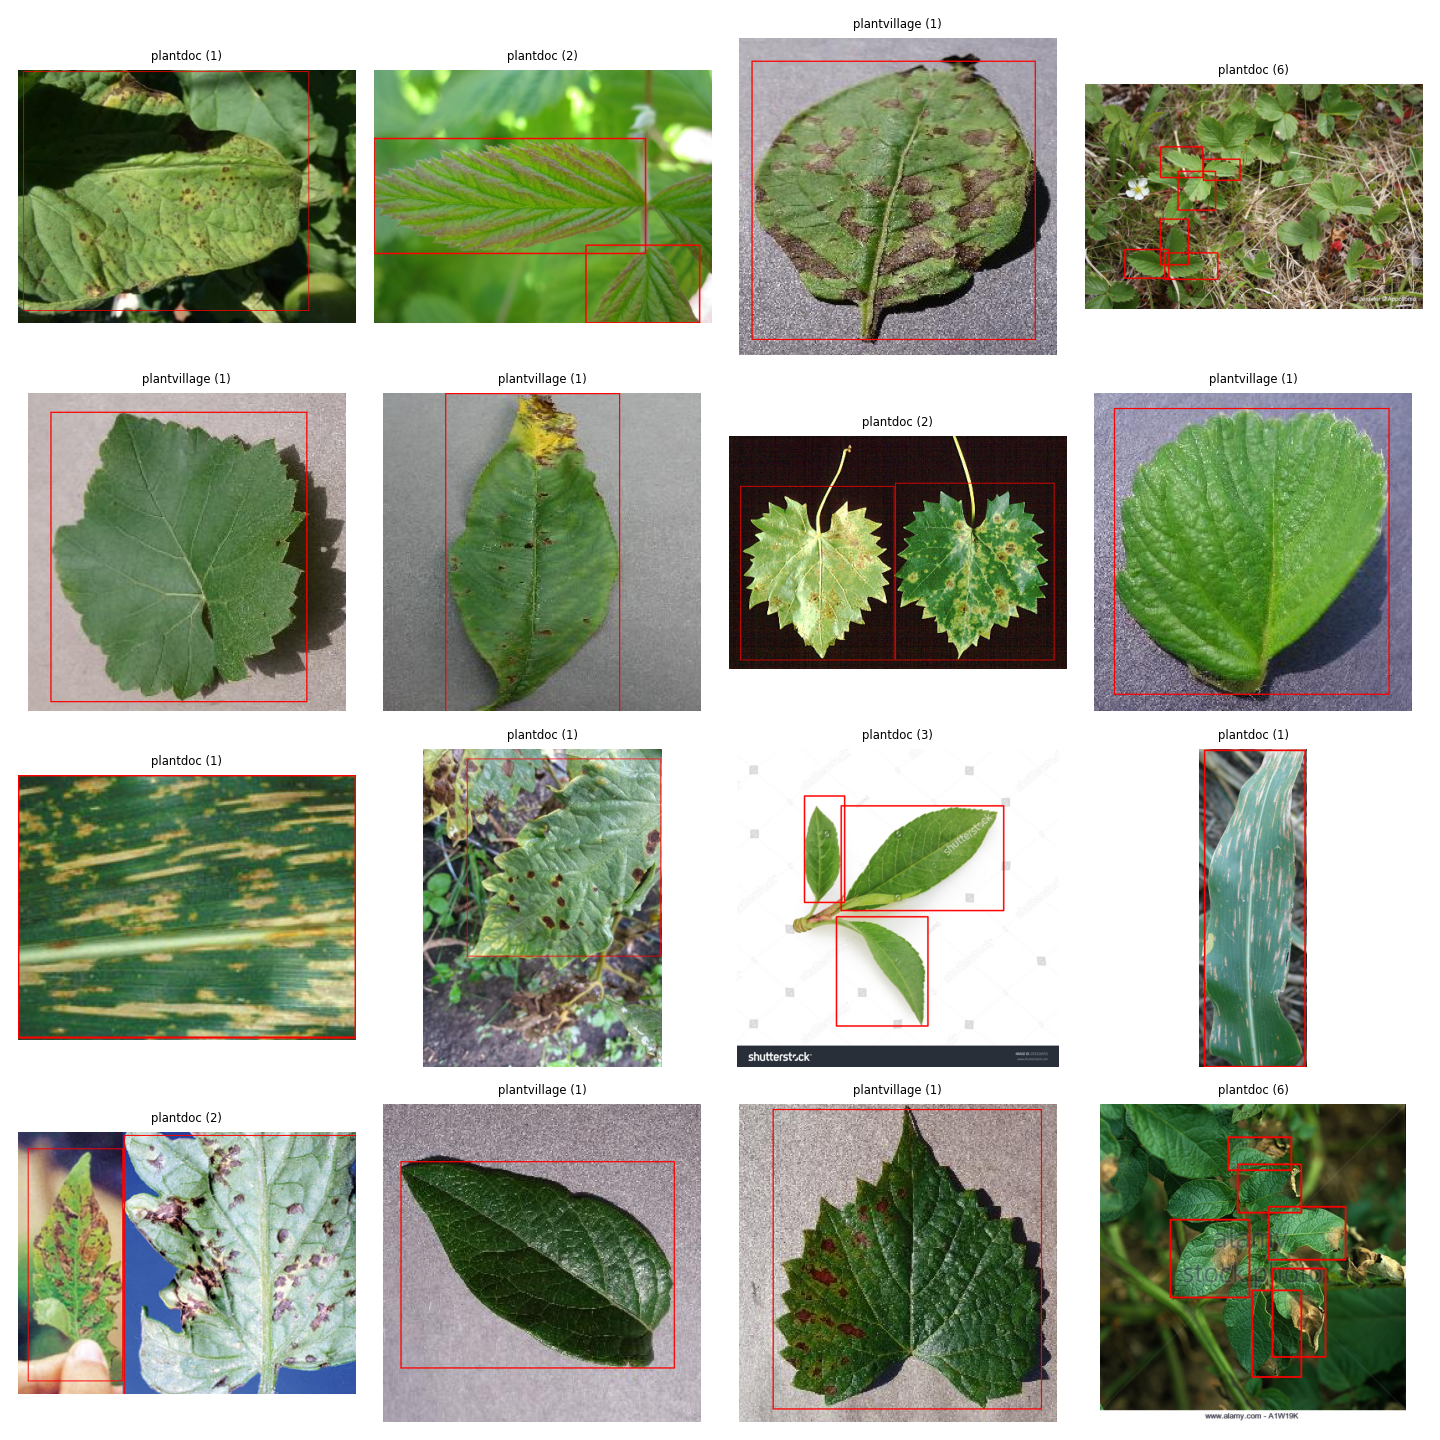

In [7]:
import pandas as pd

manifest = pd.read_parquet(YOLO_DIR / byd.MANIFEST)
byd.report(manifest)
byd.preview(YOLO_DIR, "train", path=YOLO_DIR / "preview_train.png")
display(Image(filename=YOLO_DIR / "preview_train.png"))

## Configuration

In [8]:
import yaml

from vision.train.config import apply_overrides, load_config

# Colab : tous les cœurs pour le chargement, base MLflow séparée de celle du PC.
YOLO_ENV_SET = (
    [f"yolo.workers={os.cpu_count()}", f"mlflow.tracking_uri={drive_data.COLAB_MLFLOW}"]
    if COLAB
    else []
)
cfg = apply_overrides(load_config(ROOT / CONFIG), YOLO_ENV_SET + SET)
print(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))

seed: 42
model: yolov8n.pt
data: data/yolo/data.yaml
yolo:
  imgsz: 640
  epochs: 100
  patience: 30
  batch: 16
  workers: 12
  optimizer: auto
  cos_lr: true
  close_mosaic: 10
  fraction: 1.0
  mosaic: 1.0
  mixup: 0.0
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 10.0
  flipud: 0.5
  fliplr: 0.5
  scale: 0.5
led_tint:
  p: 0.3
mlflow:
  tracking_uri: mlruns/colab/mlflow.db
  experiment: phase2-detection



## Entraînement

In [9]:
from vision.train.train_yolo import run

if YOLO_RUN is None:
    with drive_data.PeriodicSync(drive_data.OUTPUTS, DRIVE_DIR):
        YOLO_RUN = run(cfg, DEVICE).name
print("YOLO_RUN =", YOLO_RUN)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/SerreIA/data/yolo/data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchsc

INFO run a604f0445e484b6fa8e44aa45943317e : test mAP50 0.956, mAP50-95 0.778 -> /content/SerreIA/runs/a604f0445e484b6fa8e44aa45943317e


runs → /content/drive/MyDrive/SerreIA/runs/runs
reports → /content/drive/MyDrive/SerreIA/runs/reports
mlruns/colab → /content/drive/MyDrive/SerreIA/runs/mlruns/colab
YOLO_RUN = a604f0445e484b6fa8e44aa45943317e


## Courbes et métriques (val, puis test)

a604f0445e484b6fa8e44aa45943317e results.png


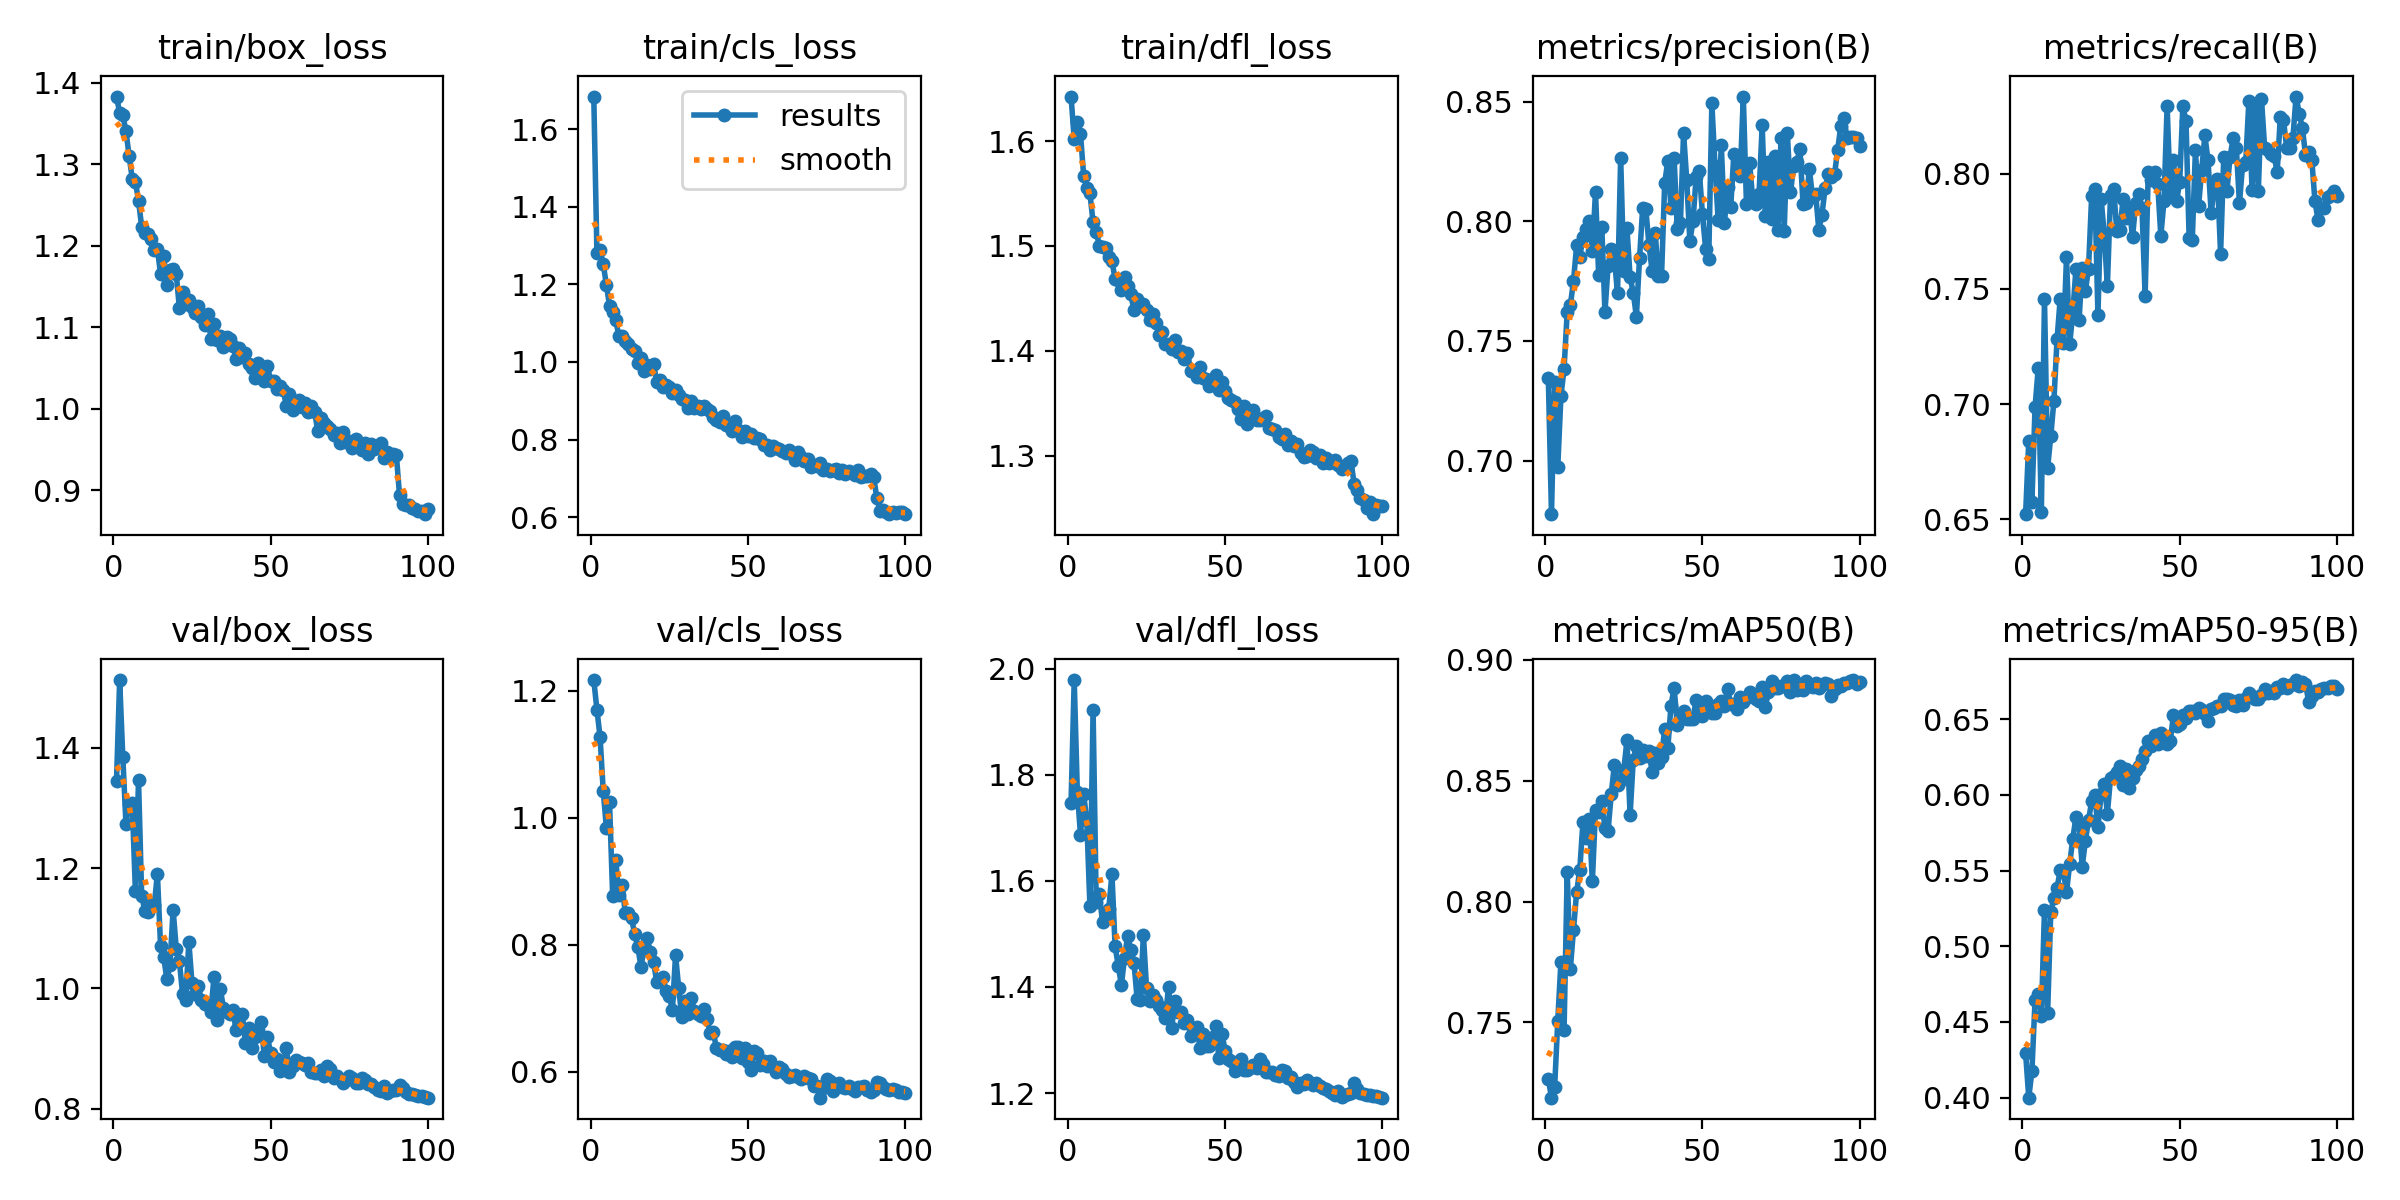

a604f0445e484b6fa8e44aa45943317e BoxPR_curve.png


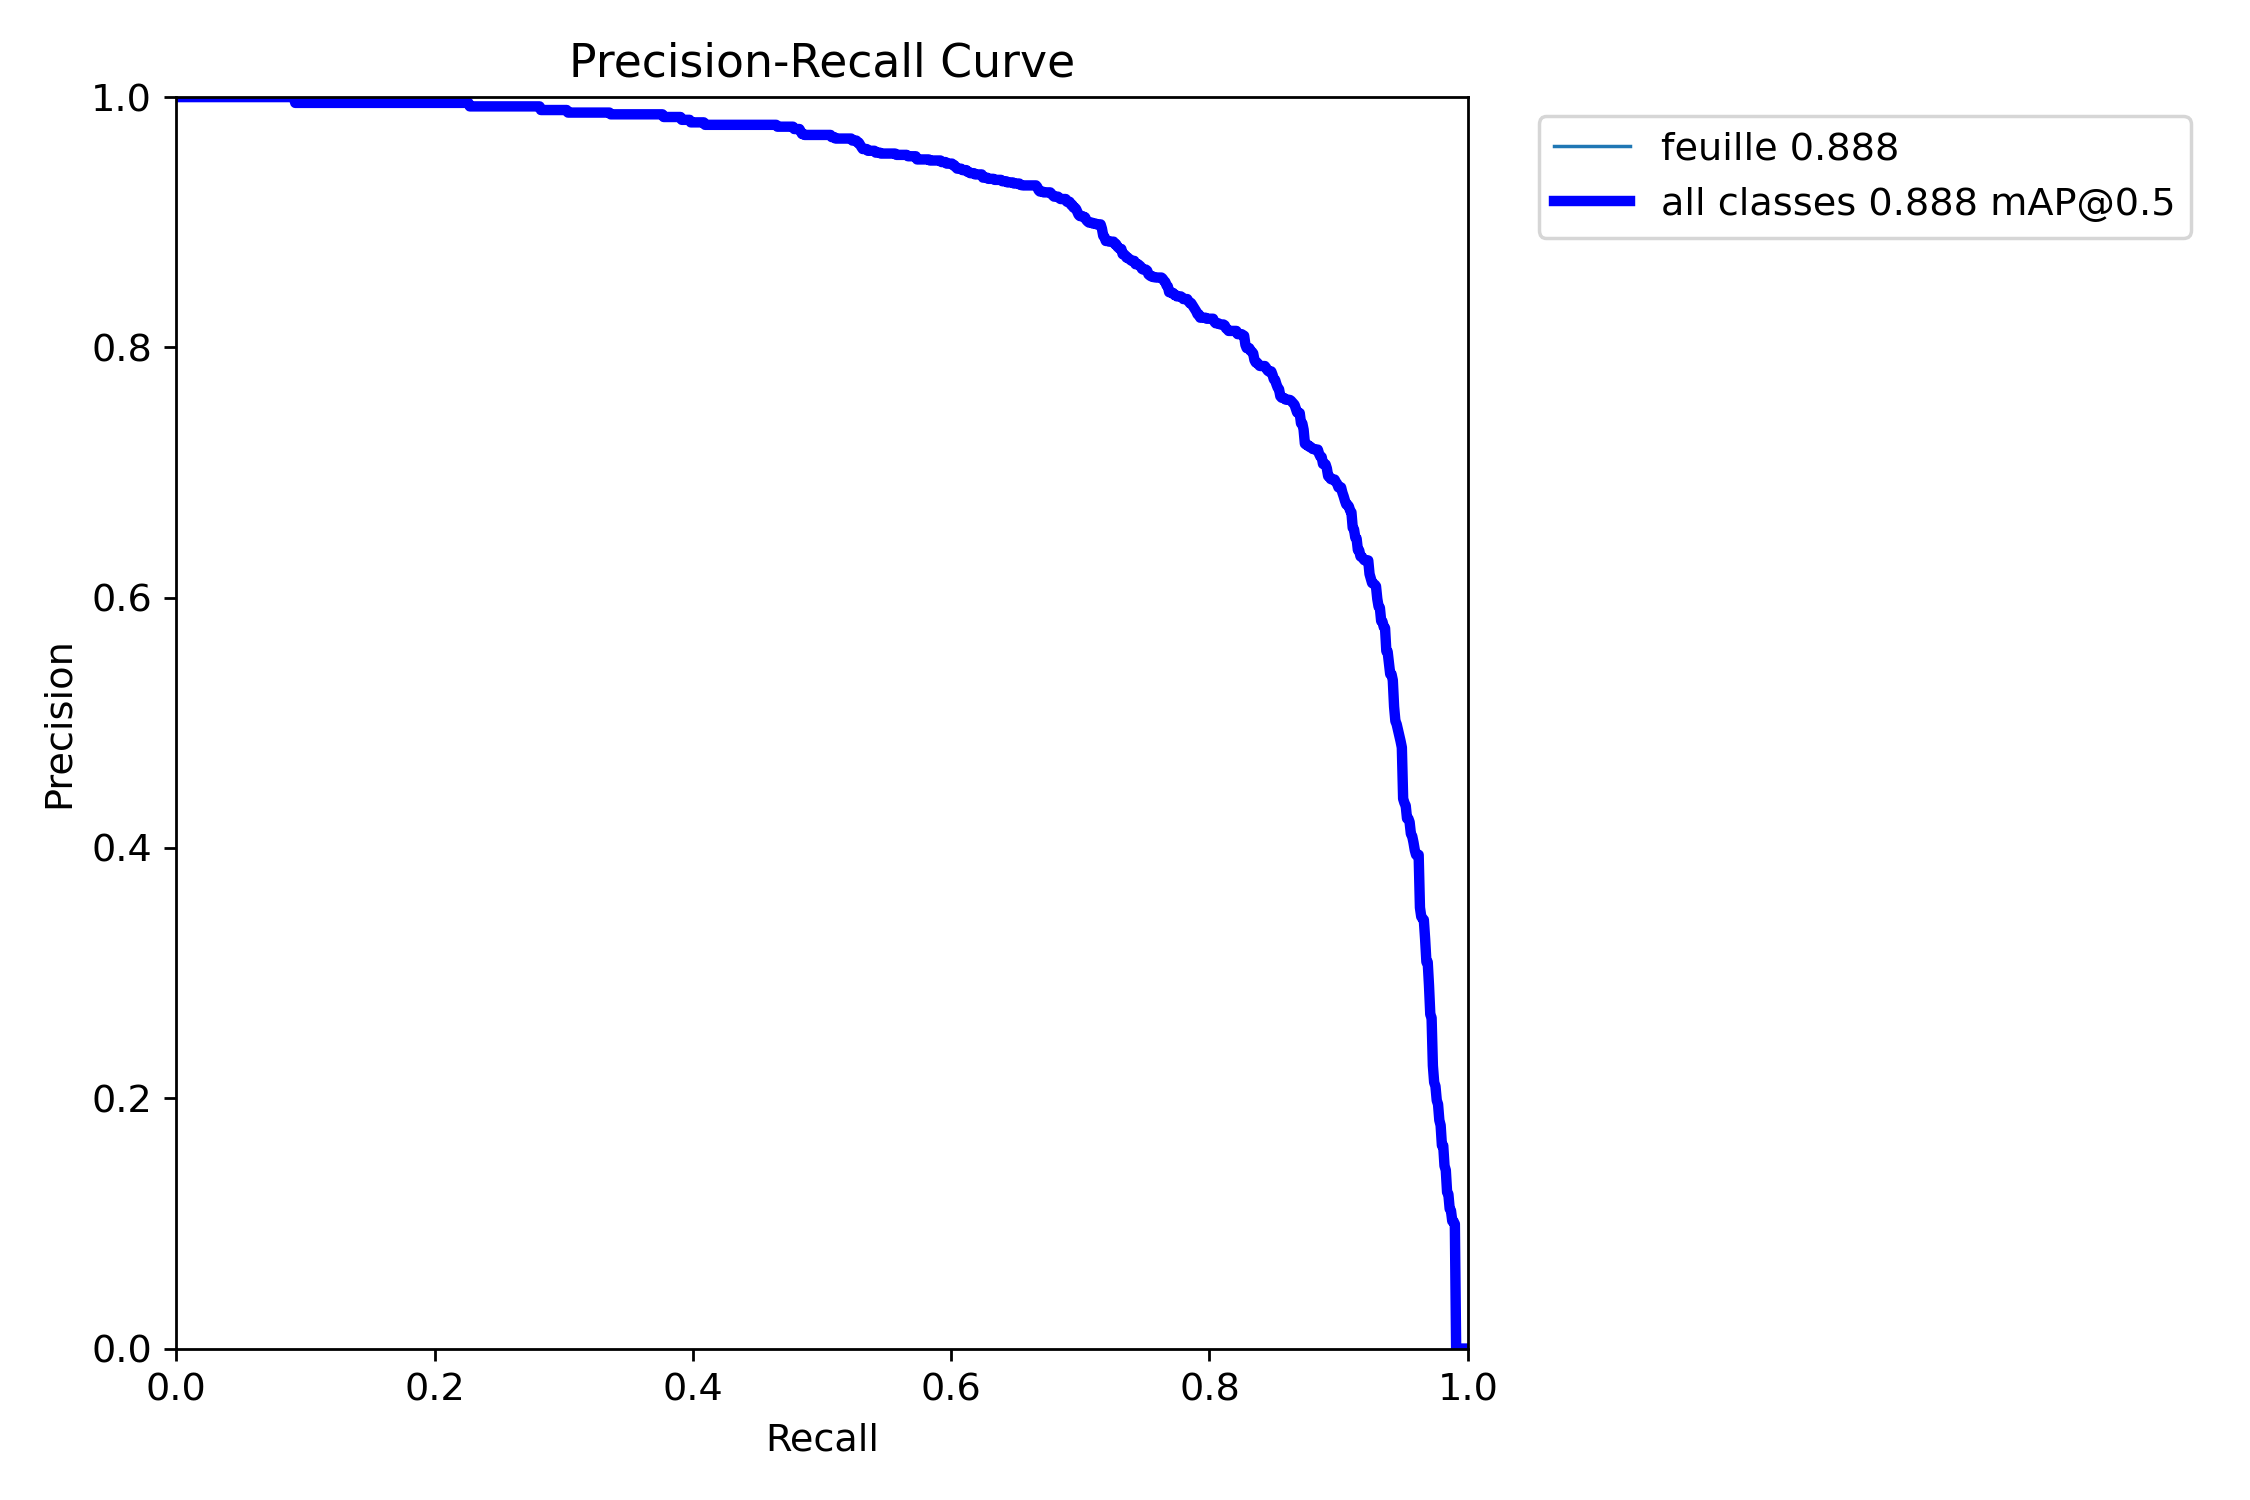

a604f0445e484b6fa8e44aa45943317e_test BoxPR_curve.png


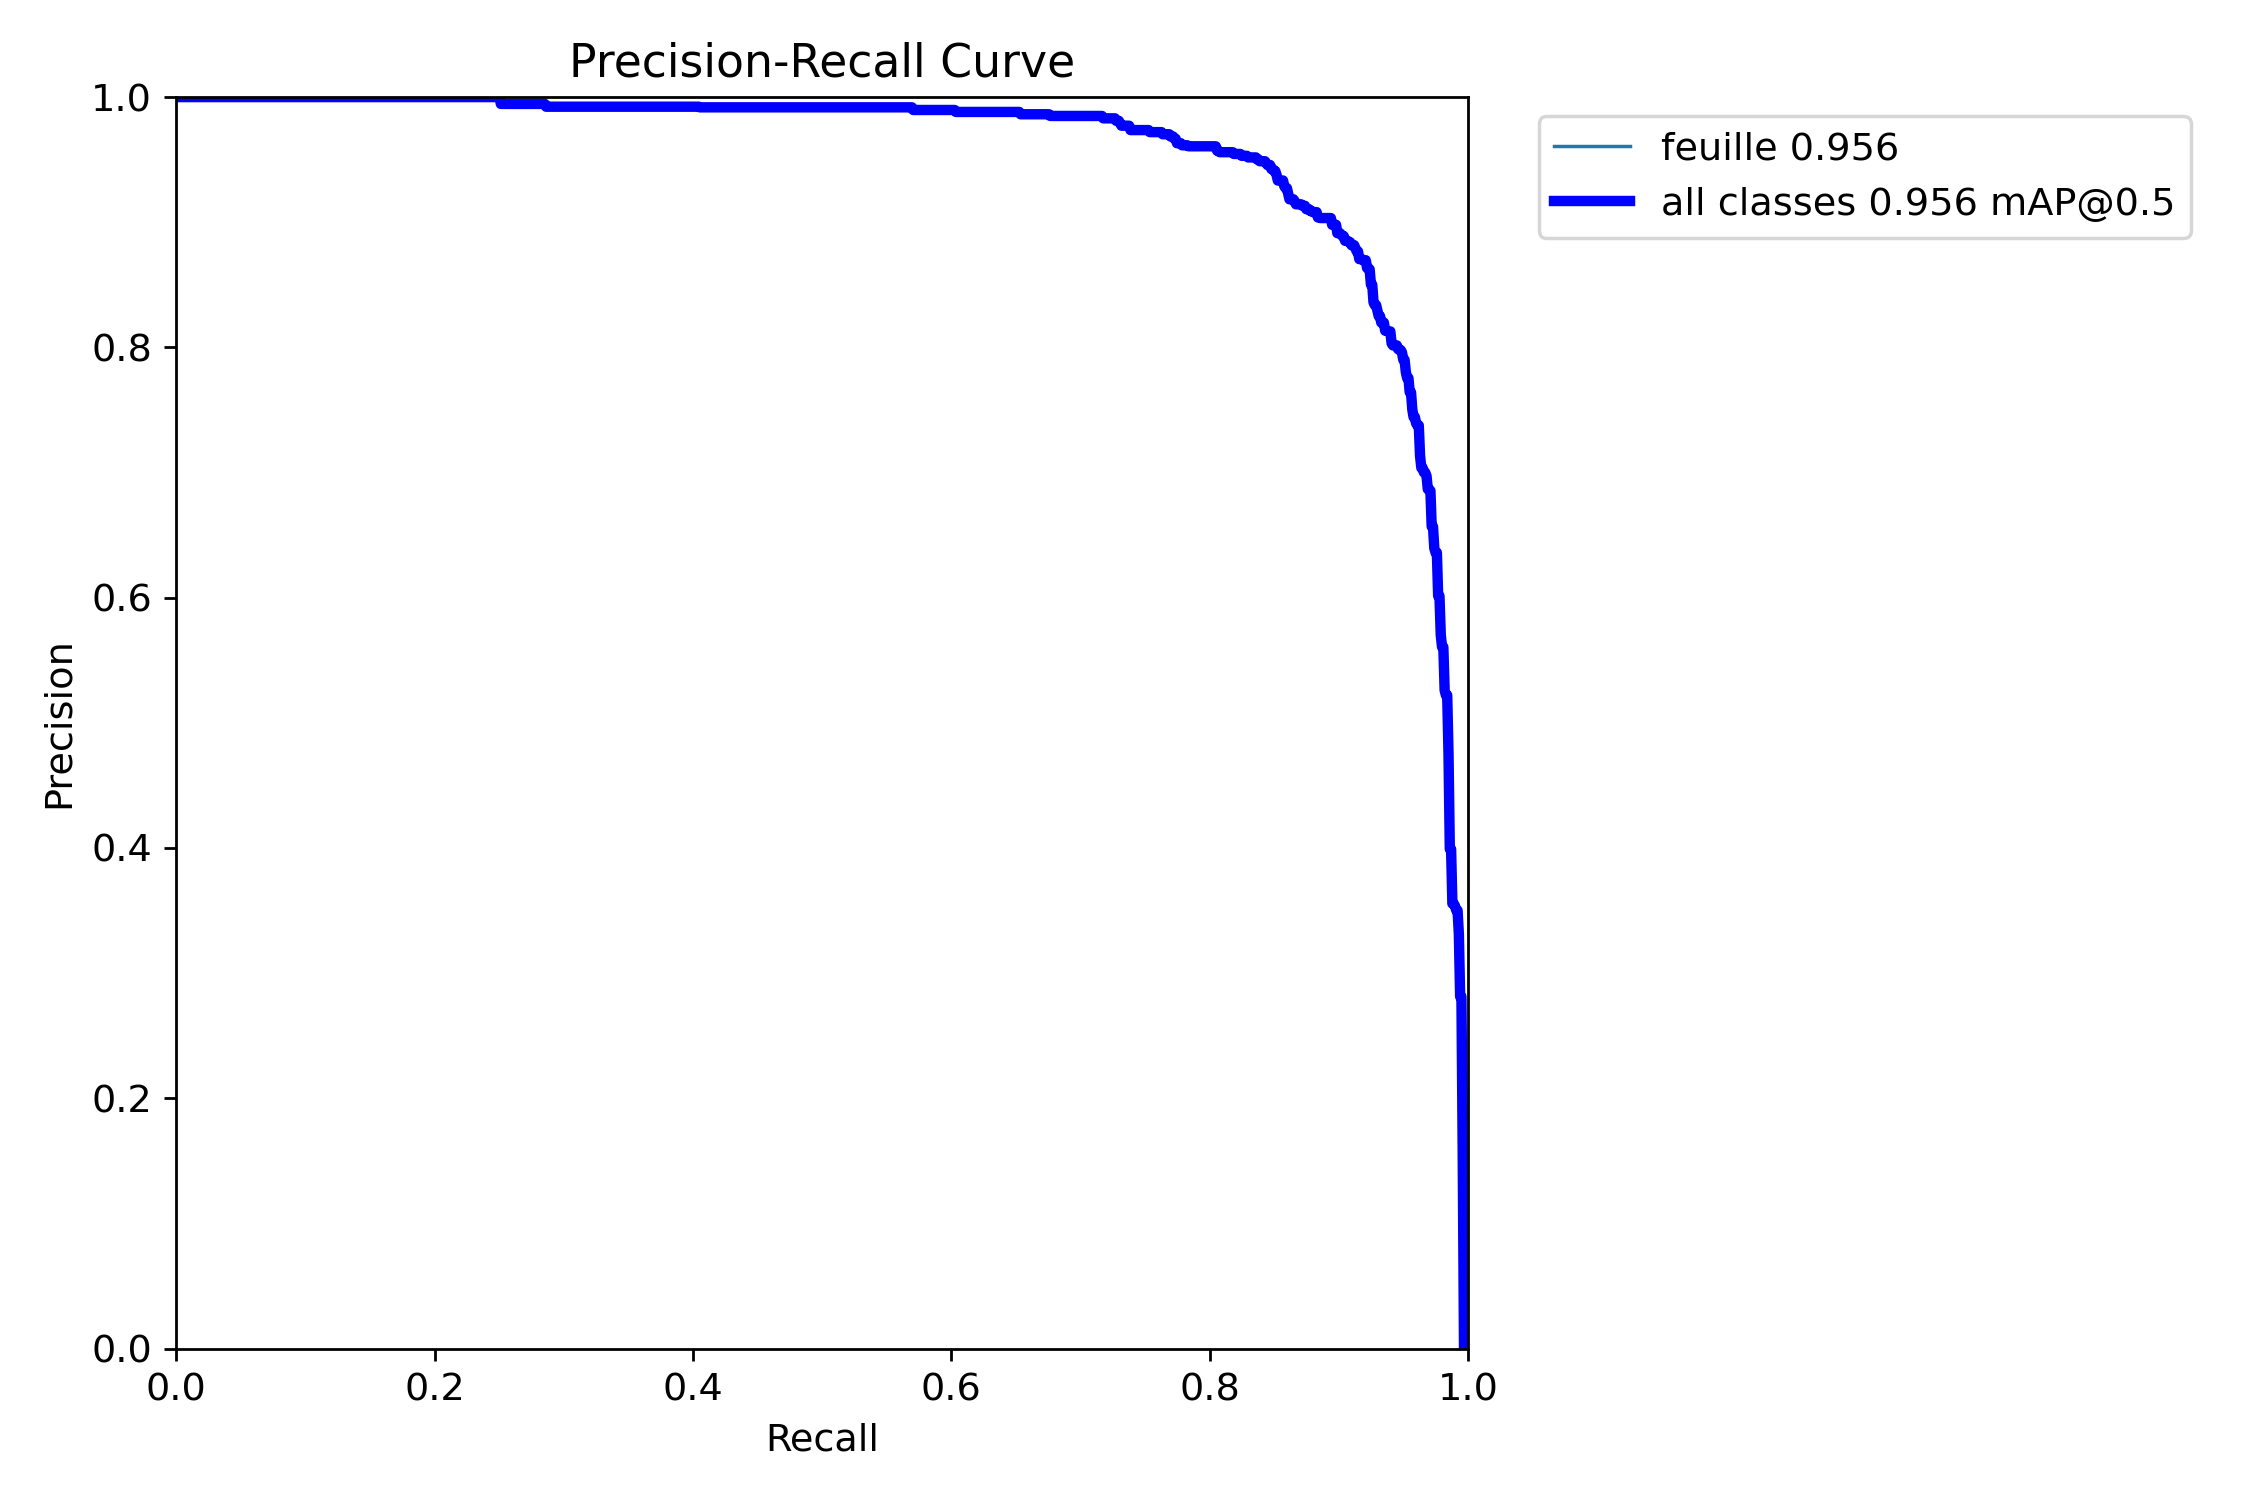

In [10]:
UL = ROOT / "runs" / "ultralytics"
for png in ["results.png", "BoxPR_curve.png"]:
    for d in [UL / YOLO_RUN, UL / f"{YOLO_RUN}_test"]:
        if (d / png).exists():
            print(d.name, png)
            display(Image(filename=d / png))

## Deux étages sur PlantDoc TEST

CLF_RUN = 96f8b511d38c414890b750f2123e3fa7
runs → /content/drive/MyDrive/SerreIA/runs/runs
reports → /content/drive/MyDrive/SerreIA/runs/reports
mlruns/colab → /content/drive/MyDrive/SerreIA/runs/mlruns/colab


,valeur
n_images,236.000000
detection/recall_feuille,0.918142
detection/precision_feuille,0.708191
feuilles/sante_accuracy,0.855422
feuilles/recall_anormal,0.962963
image/recall_plante_anormale,0.979452
image/faux_positifs_sain,0.422222
n_images_anormales,146.000000
n_images_saines,90.000000


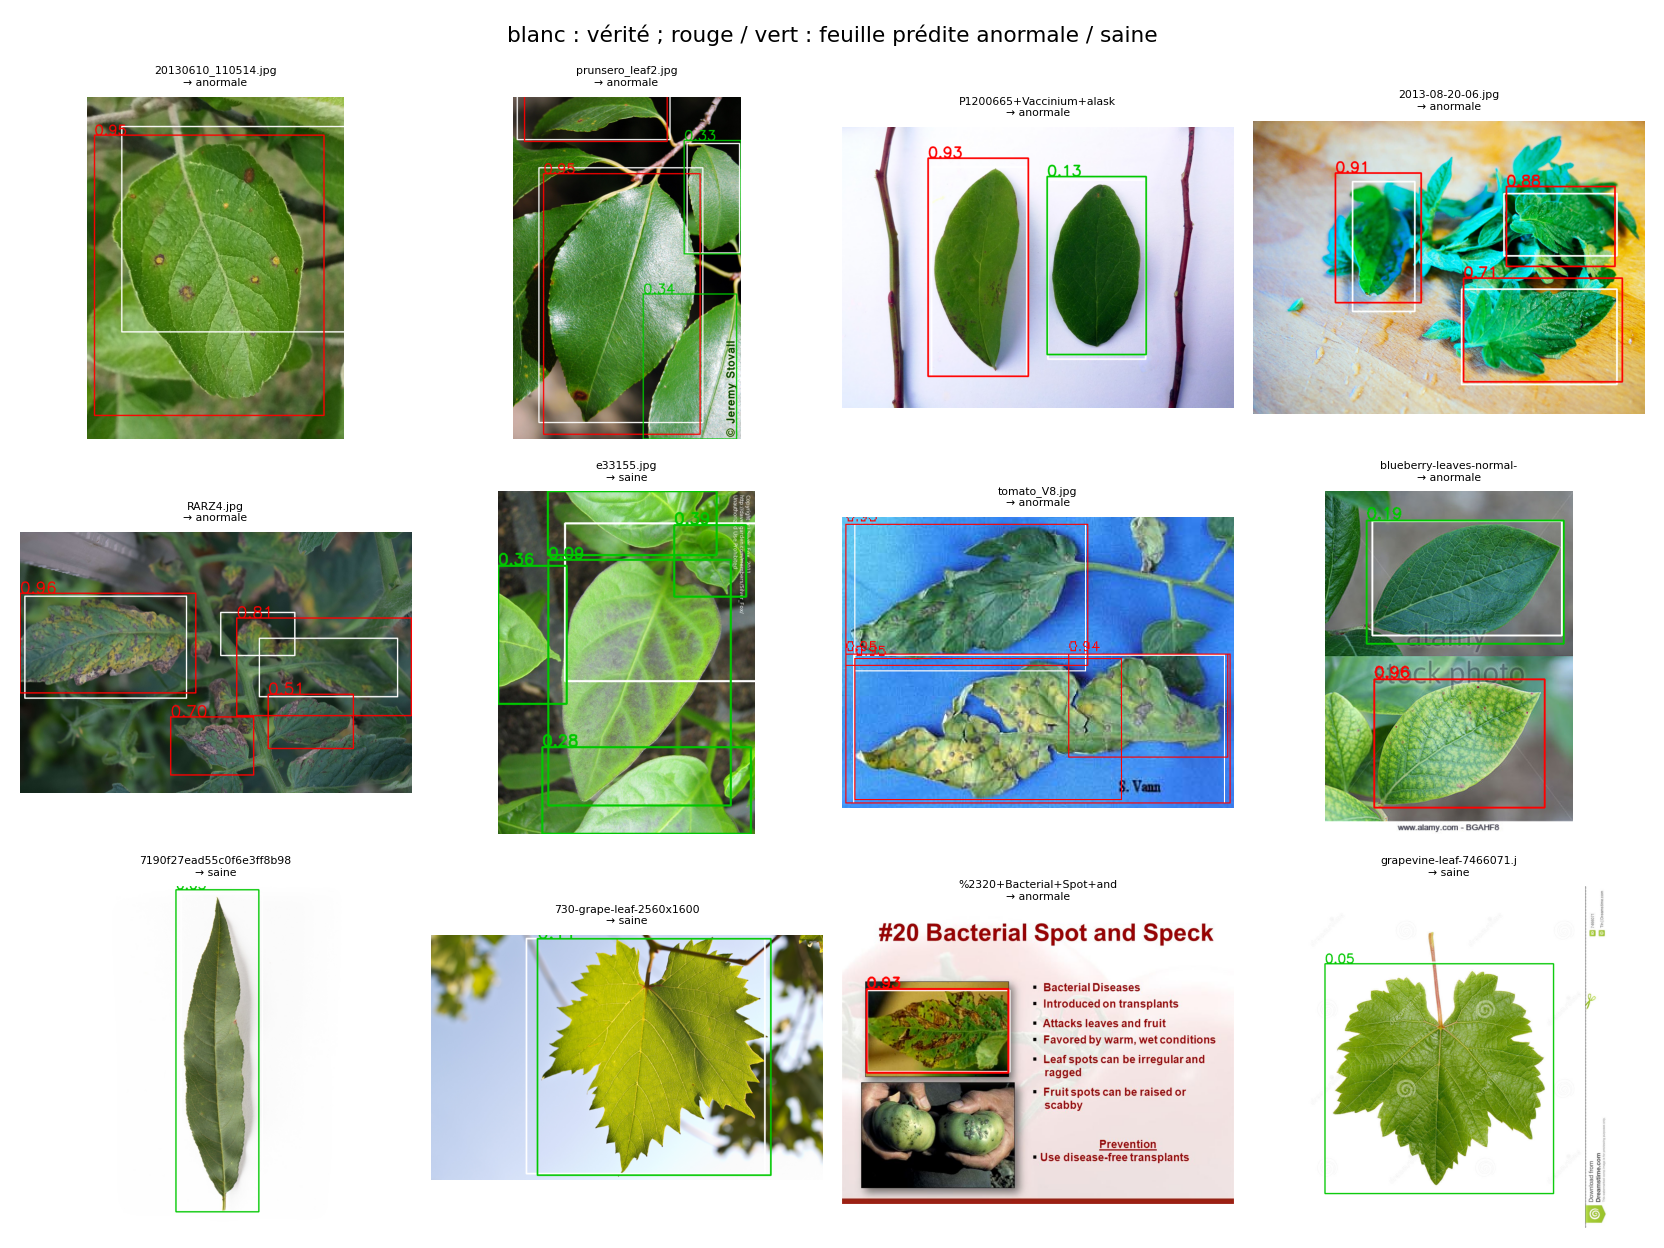

In [11]:
import json

from vision.eval.two_stage import (
    CropClassifier,
    TwoStagePipeline,
    YoloDetector,
    evaluate,
    plantdoc_scenes,
    plot_examples,
)
from vision.eval.cross_domain_eval import REPORTS_DIR
from vision.train.train_classifier import pick_device

if CLF_RUN is None:  # the YOLO runs have a runs/ultralytics/<id>/ folder
    ckpts = [p for p in (ROOT / "runs").glob("*/best.pt") if not (UL / p.parent.name).exists()]
    if not ckpts:
        raise FileNotFoundError("aucun classifieur runs/*/best.pt : notebook 02")
    CLF_RUN = max(ckpts, key=lambda p: p.stat().st_mtime).parent.name
print("CLF_RUN =", CLF_RUN)

device = pick_device(DEVICE)
pipeline = TwoStagePipeline(
    YoloDetector(ROOT / "runs" / YOLO_RUN / "best.pt", device=str(device)),
    CropClassifier(ROOT / "runs" / CLF_RUN / "best.pt", device),
)
scenes = plantdoc_scenes(DATA_DIR, "test")
scenes = scenes[:LIMIT] if LIMIT else scenes
metrics, results = evaluate(pipeline, scenes)
OUT = REPORTS_DIR / CLF_RUN
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "two_stage_test.json").write_text(json.dumps(metrics, indent=1))
plot_examples(scenes, results, OUT / "two_stage_test.png")
drive_data.sync_all(DRIVE_DIR)
display(pd.Series(metrics).to_frame("valeur"))
display(Image(filename=OUT / "two_stage_test.png"))

## Résumé

Détecteur : `runs/<YOLO_RUN>/best.pt` (courbes dans `runs/ultralytics/<YOLO_RUN>/`) ;
deux étages : `reports/<CLF_RUN>/two_stage_test.{json,png}`. Critère de la feuille de
route (docs/07) : mAP@0.5 « feuille » ≥ 0,6. Suite : pseudo-labels SAM 2 et Label
Studio (`python -m vision.labeling.pseudo_labels`, docs/04 §2).